# Case Study 3: E-Commerce Customer Segmentation

This notebook groups customers using **RFM (Recency, Frequency, Monetary)** features. It applies **K-Means** and **DBSCAN**, reduces the data with **PCA**, visualizes customer groups with **t-SNE**, and suggests marketing actions for each customer persona.

In [3]:
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn

In [4]:
import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [5]:
path = kagglehub.dataset_download("carrie1/ecommerce-data")

print("Dataset path:", path)

Using Colab cache for faster access to the 'ecommerce-data' dataset.
Dataset path: /kaggle/input/ecommerce-data


In [6]:
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("CSV files found:", csv_files)

CSV files found: ['/kaggle/input/ecommerce-data/data.csv']


In [7]:
file_path = csv_files[0]

df = pd.read_csv(file_path, encoding="ISO-8859-1")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [8]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

Dataset shape: (541909, 8)

Column names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [10]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [12]:
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [13]:
df.columns = df.columns.str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df = df.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"])
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df.drop_duplicates()
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [14]:
print("Shape after cleaning:", df.shape)
print("Number of customers:", df["CustomerID"].nunique())
print("Missing values after cleaning:", df.isnull().sum().sum())
print("First invoice date:", df["InvoiceDate"].min())
print("Last invoice date:", df["InvoiceDate"].max())

Shape after cleaning: (392692, 9)
Number of customers: 4338
Missing values after cleaning: 0
First invoice date: 2010-12-01 08:26:00
Last invoice date: 2011-12-09 12:50:00


In [15]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [16]:
print("RFM table shape:", rfm.shape)
rfm.describe().round(2)

RFM table shape: (4338, 3)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


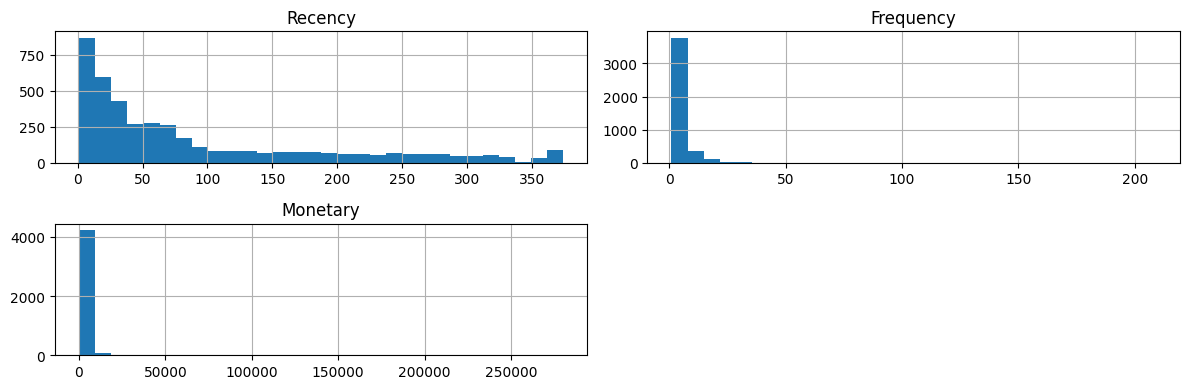

In [17]:
rfm[["Recency", "Frequency", "Monetary"]].hist(figsize=(12, 4), bins=30)
plt.tight_layout()
plt.show()

In [18]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled data shape:", rfm_scaled.shape)

Scaled data shape: (4338, 3)


In [19]:
k_values = range(2, 9)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(
            rfm_scaled,
            labels,
            sample_size=min(2000, len(rfm_scaled)),
            random_state=42
        )
    )

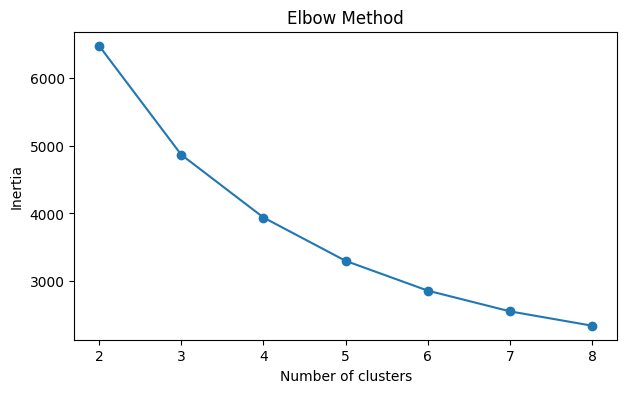

In [20]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

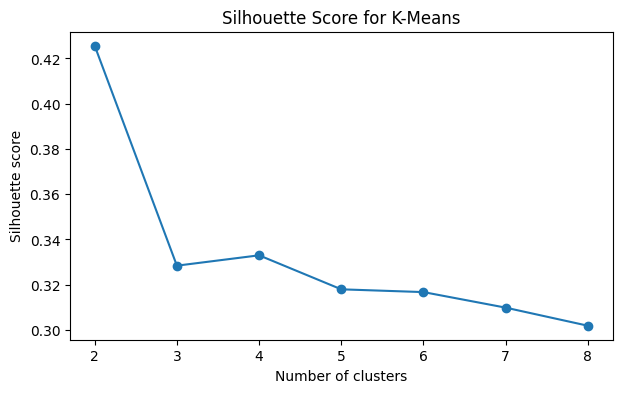

In [21]:
plt.figure(figsize=(7, 4))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for K-Means")
plt.show()

In [22]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,KMeans_Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1


In [23]:
print("Customers in each K-Means cluster:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

Customers in each K-Means cluster:
KMeans_Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [24]:
kmeans_summary = rfm.groupby("KMeans_Cluster").agg(
    Customer_Count=("KMeans_Cluster", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

kmeans_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
KMeans_Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


In [25]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm_scaled)

pca_data = pd.DataFrame(pca_result, columns=["PCA1", "PCA2"], index=rfm.index)
pca_data["KMeans_Cluster"] = rfm["KMeans_Cluster"]

print("Variance explained by the two PCA components:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the two PCA components: 0.939


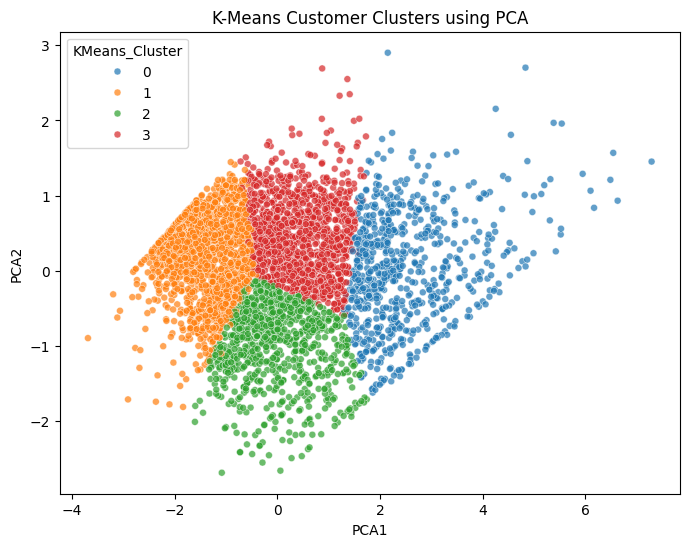

In [26]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_data,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)
plt.title("K-Means Customer Clusters using PCA")
plt.show()

In [27]:
dbscan = DBSCAN(eps=0.7, min_samples=10)

dbscan_labels = dbscan.fit_predict(rfm_scaled)
rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN labels and customer counts:")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

number_of_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print("Number of DBSCAN clusters, excluding noise:", number_of_dbscan_clusters)
print("Number of noise customers:", int((dbscan_labels == -1).sum()))

DBSCAN labels and customer counts:
DBSCAN_Cluster
-1      39
 0    4299
Name: count, dtype: int64
Number of DBSCAN clusters, excluding noise: 1
Number of noise customers: 39


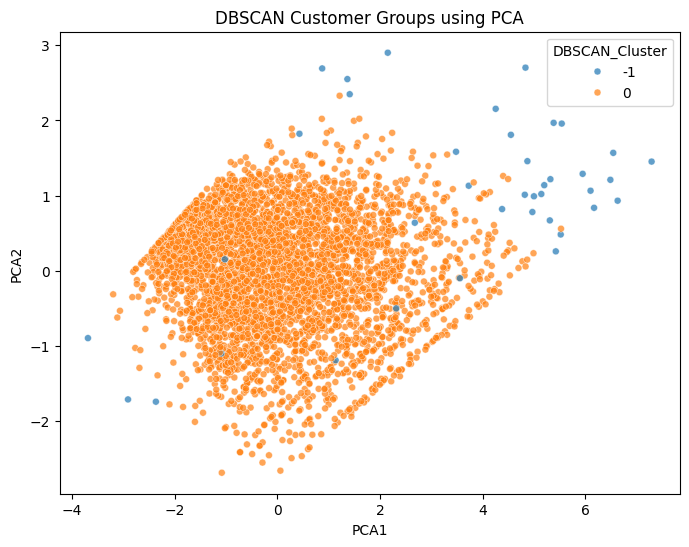

In [28]:
pca_data["DBSCAN_Cluster"] = rfm["DBSCAN_Cluster"]

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_data,
    x="PCA1",
    y="PCA2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)
plt.title("DBSCAN Customer Groups using PCA")
plt.show()

In [29]:
sample_size = min(1500, len(rfm_scaled))
sample_positions = np.random.RandomState(42).choice(
    len(rfm_scaled),
    size=sample_size,
    replace=False
)

sample_scaled = rfm_scaled[sample_positions]
perplexity_value = min(30, max(2, (sample_size - 1) // 3))

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perplexity_value,
    init="pca",
    learning_rate="auto"
)

tsne_result = tsne.fit_transform(sample_scaled)

tsne_data = pd.DataFrame(tsne_result, columns=["TSNE1", "TSNE2"])
tsne_data["KMeans_Cluster"] = rfm["KMeans_Cluster"].iloc[sample_positions].to_numpy()
tsne_data["DBSCAN_Cluster"] = rfm["DBSCAN_Cluster"].iloc[sample_positions].to_numpy()

tsne_data.head()

,TSNE1,TSNE2,KMeans_Cluster,DBSCAN_Cluster
0,-33.437733,-25.433472,1,0
1,-8.626242,28.006636,1,0
2,4.788009,-4.253518,2,0
3,28.010700,-7.950150,2,0
4,-32.053146,4.335948,1,0


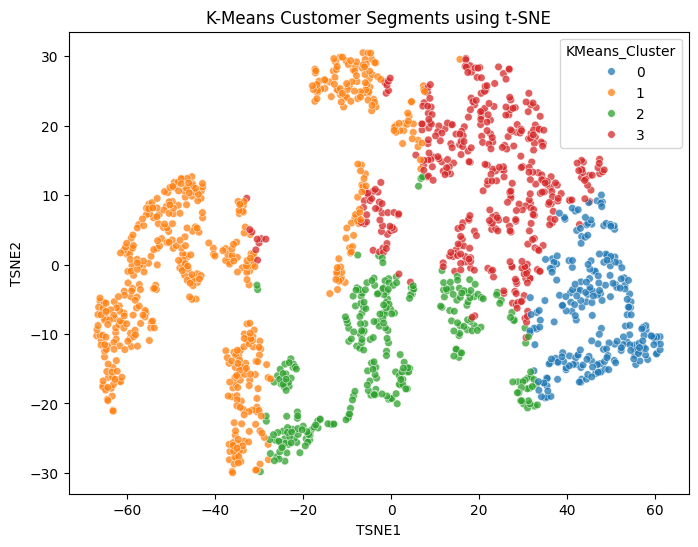

In [30]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tsne_data,
    x="TSNE1",
    y="TSNE2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=30,
    alpha=0.75
)
plt.title("K-Means Customer Segments using t-SNE")
plt.show()

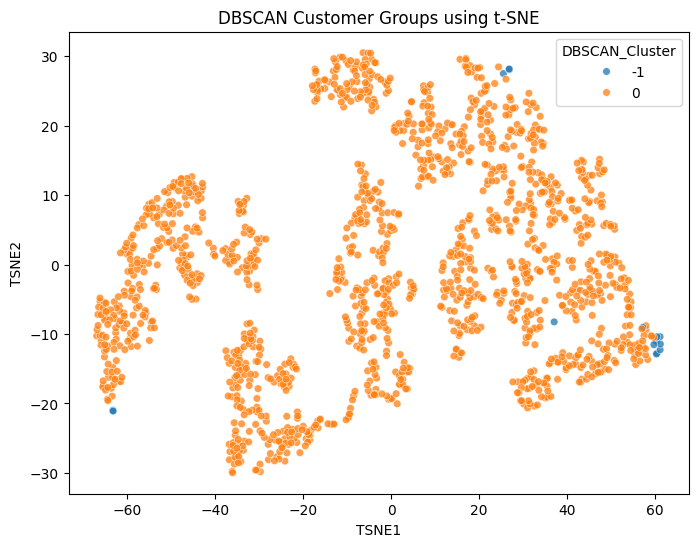

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=tsne_data,
    x="TSNE1",
    y="TSNE2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=30,
    alpha=0.75
)
plt.title("DBSCAN Customer Groups using t-SNE")
plt.show()

In [32]:
median_recency = rfm["Recency"].median()
median_frequency = rfm["Frequency"].median()
median_monetary = rfm["Monetary"].median()

def get_persona(row):
    if row["Avg_Recency"] <= median_recency and row["Avg_Frequency"] >= median_frequency and row["Avg_Monetary"] >= median_monetary:
        return "Champions"
    elif row["Avg_Recency"] > median_recency and row["Avg_Frequency"] >= median_frequency:
        return "At-Risk Loyal Customers"
    elif row["Avg_Monetary"] >= median_monetary and row["Avg_Frequency"] < median_frequency:
        return "Big-Spender Occasional Buyers"
    elif row["Avg_Recency"] <= median_recency and row["Avg_Frequency"] < median_frequency:
        return "Recent / Low-Frequency Customers"
    else:
        return "Needs Nurturing / Dormant Customers"

In [33]:
marketing_actions = {
    "Champions": "Reward loyalty, offer early access, and encourage referrals.",
    "At-Risk Loyal Customers": "Send personalized win-back messages and limited-time return offers.",
    "Big-Spender Occasional Buyers": "Recommend related products and offer bundles suited to past purchases.",
    "Recent / Low-Frequency Customers": "Send a welcome sequence and an incentive for a second purchase.",
    "Needs Nurturing / Dormant Customers": "Try a low-cost reactivation campaign and avoid repeated costly offers.",
    "Noise / Unusual Patterns": "Review these customers individually before choosing a campaign."
}

persona_summary = kmeans_summary.copy()
persona_summary["Persona"] = persona_summary.apply(get_persona, axis=1)
persona_summary["Marketing_Action"] = persona_summary["Persona"].map(marketing_actions)

persona_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing_Action
KMeans_Cluster,,,,,,
0,713,12.17,13.75,8088.02,Champions,"Reward loyalty, offer early access, and encour..."
1,1622,181.51,1.32,341.00,Needs Nurturing / Dormant Customers,Try a low-cost reactivation campaign and avoid...
2,837,17.70,2.19,557.32,Needs Nurturing / Dormant Customers,Try a low-cost reactivation campaign and avoid...
3,1166,71.64,4.08,1801.78,At-Risk Loyal Customers,Send personalized win-back messages and limite...


In [34]:
dbscan_summary = rfm.groupby("DBSCAN_Cluster").agg(
    Customer_Count=("DBSCAN_Cluster", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

def get_dbscan_persona(row):
    if row.name == -1:
        return "Noise / Unusual Patterns"
    return get_persona(row)

dbscan_summary["Persona"] = dbscan_summary.apply(get_dbscan_persona, axis=1)
dbscan_summary["Marketing_Action"] = dbscan_summary["Persona"].map(marketing_actions)

dbscan_summary

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing_Action
DBSCAN_Cluster,,,,,,
-1,39,54.67,45.74,61636.59,Noise / Unusual Patterns,Review these customers individually before cho...
0,4299,92.88,3.90,1508.11,At-Risk Loyal Customers,Send personalized win-back messages and limite...


In [35]:
comparison = pd.DataFrame({
    "Method": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [
        rfm["KMeans_Cluster"].nunique(),
        number_of_dbscan_clusters
    ],
    "Noise_Customers": [
        0,
        int((rfm["DBSCAN_Cluster"] == -1).sum())
    ]
})

comparison

,Method,Number_of_Clusters,Noise_Customers
0,K-Means,4,0
1,DBSCAN,1,39
